# Catalog visualizations

This notebook creates the project visualizations from the canonical catalog. It reads the data only and writes charts and a small summary under `reports/eda/notebook/`. The classifier target remains SATCAT `OBJECT_TYPE`; these charts are descriptive and are not collision-risk predictions.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd

candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next(path for path in candidates if (path / 'data' / 'review3_catalog.csv').exists())
INPUT = ROOT / 'data' / 'review3_catalog.csv'
OUTPUT = ROOT / 'reports' / 'eda' / 'notebook'
OUTPUT.mkdir(parents=True, exist_ok=True)
print(f'input={INPUT}')
print(f'output={OUTPUT}')

input=C:\space-debris-collision-risk-output\project\data\review3_catalog.csv
output=C:\space-debris-collision-risk-output\project\reports\eda\notebook


In [2]:
columns = ['norad_id', 'epoch', 'inclination', 'altitude_km', 'OBJECT_TYPE', 'period_min']
df = pd.read_csv(INPUT, usecols=columns)
for column in ['inclination', 'altitude_km', 'period_min']:
    df[column] = pd.to_numeric(df[column], errors='coerce')
df['OBJECT_TYPE'] = df['OBJECT_TYPE'].replace({'UNKNOWN': 'UNK'}).fillna('UNK')
print(f'rows={len(df)}')
print(df[['inclination', 'altitude_km', 'period_min']].describe().round(3))
print(df['OBJECT_TYPE'].value_counts().sort_index())

rows=100000
       inclination  altitude_km  period_min
count   100000.000   100000.000  100000.000
mean        69.515     3126.304     212.817
std         28.743     8647.405     353.722
min          0.000       84.450      87.386
25%         53.054      545.850      95.574
50%         74.022      621.535      99.213
75%         97.548      904.520     107.150
max        152.856   118517.400    7694.391
OBJECT_TYPE
DEB    29723
PAY    60993
R/B     8237
UNK     1047
Name: count, dtype: int64


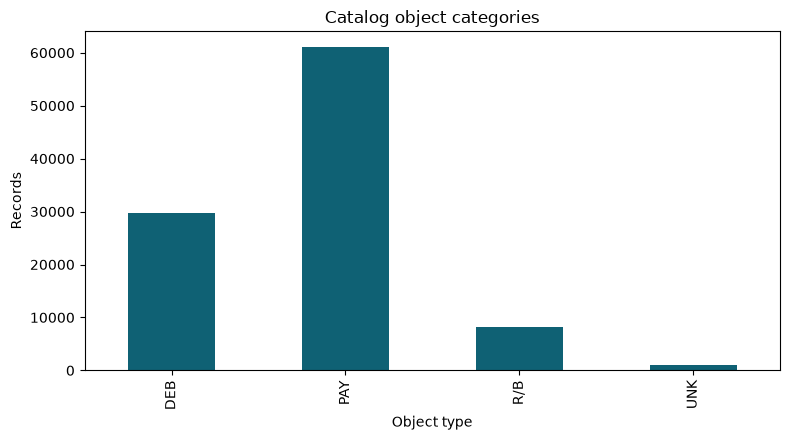

In [3]:
plt.figure(figsize=(8, 4.5))
df['OBJECT_TYPE'].value_counts().sort_index().plot(kind='bar', color='#0f6174')
plt.title('Catalog object categories')
plt.xlabel('Object type')
plt.ylabel('Records')
plt.tight_layout()
plt.savefig(OUTPUT / 'object_type_counts.png', dpi=160)
plt.show()

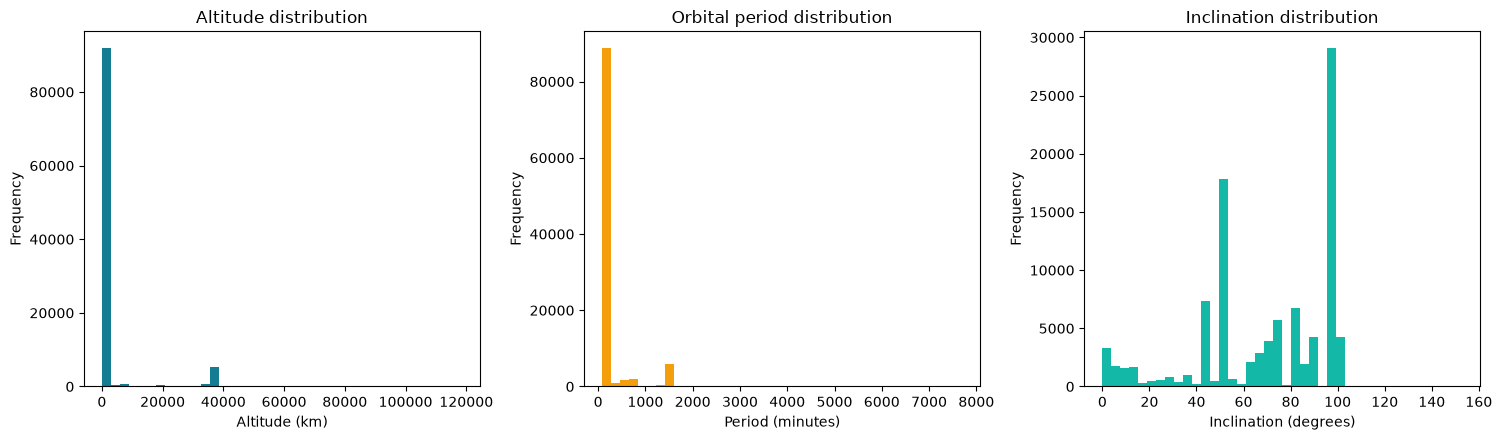

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
df['altitude_km'].dropna().plot.hist(bins=40, ax=axes[0], color='#147d92')
axes[0].set_title('Altitude distribution')
axes[0].set_xlabel('Altitude (km)')
df['period_min'].dropna().plot.hist(bins=40, ax=axes[1], color='#f59e0b')
axes[1].set_title('Orbital period distribution')
axes[1].set_xlabel('Period (minutes)')
df['inclination'].dropna().plot.hist(bins=40, ax=axes[2], color='#14b8a6')
axes[2].set_title('Inclination distribution')
axes[2].set_xlabel('Inclination (degrees)')
fig.tight_layout()
fig.savefig(OUTPUT / 'orbital_feature_distributions.png', dpi=160)
plt.show()

In [5]:
summary = {
    'rows': int(len(df)),
    'object_type_counts': {str(k): int(v) for k, v in df['OBJECT_TYPE'].value_counts().sort_index().items()},
    'missing_values': {str(k): int(v) for k, v in df.isna().sum().items()},
    'charts': ['object_type_counts.png', 'orbital_feature_distributions.png'],
}
(OUTPUT / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print(json.dumps(summary, indent=2))

{
  "rows": 100000,
  "object_type_counts": {
    "DEB": 29723,
    "PAY": 60993,
    "R/B": 8237,
    "UNK": 1047
  },
  "missing_values": {
    "norad_id": 0,
    "epoch": 0,
    "inclination": 0,
    "altitude_km": 0,
    "OBJECT_TYPE": 0,
    "period_min": 0
  },
  "charts": [
    "object_type_counts.png",
    "orbital_feature_distributions.png"
  ]
}
